# Sentences: from word cutting to a 1D CNN

This notebook covers everything after the isolated-word model (`explore_dataset.ipynb`, `train_classifier.ipynb`):
why cutting words by loudness fails on sentences, the CNN that replaced it, how it is trained, and how it did on the
real board. All numbers below are **recomputed here** from the data and the saved checkpoints in `models/`.

Contents
1. The continuous recording, and why loudness cannot find word boundaries
2. The old approach on real sentences (energy cutter + 29 DSP features)
3. The CNN: synthetic sentences, fine-tuning on real ones, held-out comparison
4. What the CNN sees (probabilities over time)
5. Where it fails
6. Is the firmware code the same model? (C++ vs PyTorch)
7. The live test on the board
8. Cost on the chip, and what is not proven

Terms: a **frame** is 16 ms of audio (256 samples at 16 kHz). **Exact** = the keywords found are exactly the ones in the prompt, in order
(repeats of one keyword collapsed). **Keyword error rate** = (substituted + missed + extra keywords) / expected keywords.

In [1]:
import os, sys, json, glob, subprocess, warnings
warnings.filterwarnings("ignore")
os.chdir("..")                                   # run from the repo root: dataset/, models/ ... are relative to it
sys.path.insert(0, "tools")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import kws, voice_features as vf
from kws import *
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
real = load_real()                               # real prompts that contain exactly one utterance
print(len(real), "real prompts from", len(glob.glob("dataset_raw/session_*.wav")), "recording session(s);",
      sum(len(u["want"]) for u in real), "keywords in total")

74 real prompts from 1 recording session(s); 133 keywords in total


## 1. The continuous recording, and why loudness cannot find word boundaries
`tools/raw_session.py` recorded the board's own audio for five minutes while prompts appeared on a timer.
Below: frame loudness (RMS, DC removed) for a few prompts. The old firmware starts a word when loudness is above **300**
and ends it after 4 quiet frames (below **120**).

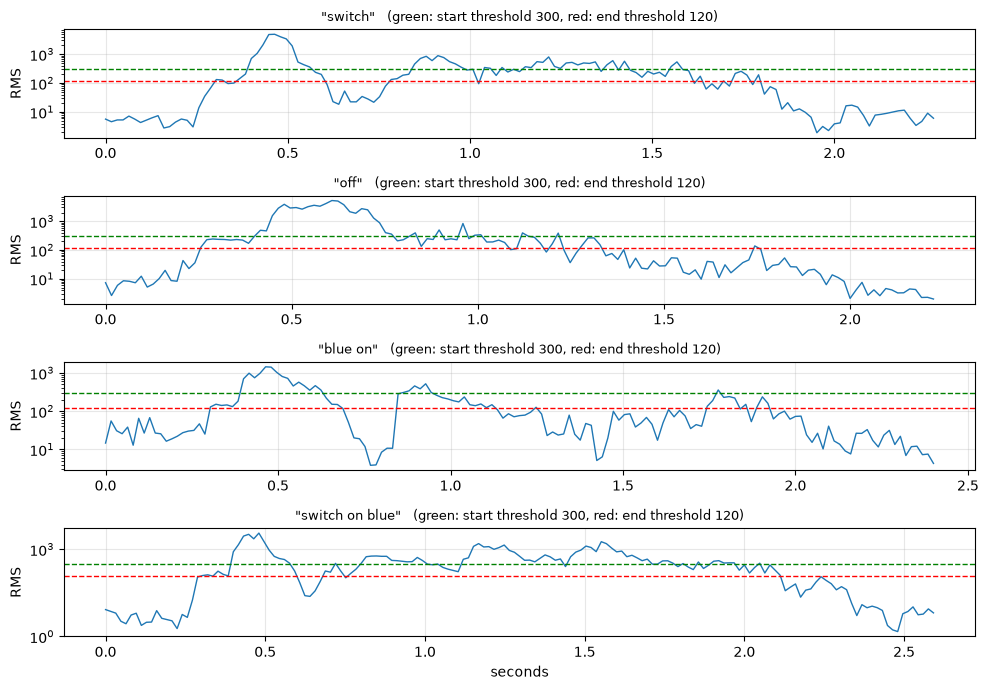

In [2]:
show = ["switch", "off", "blue on", "switch on blue"]
fig, axs = plt.subplots(len(show), 1, figsize=(10, 7), sharex=False)
for ax, name in zip(axs, show):
    u = next(u for u in real if u["text"] == name)
    r = frame_rms(u["frames"])
    ax.semilogy(np.arange(len(r)) * 0.016, np.maximum(r, 1), lw=1)
    ax.axhline(300, color="g", ls="--", lw=1); ax.axhline(120, color="r", ls="--", lw=1)
    ax.set_title(f'"{name}"   (green: start threshold 300, red: end threshold 120)', fontsize=9); ax.set_ylabel("RMS")
axs[-1].set_xlabel("seconds"); fig.tight_layout()

Count the **internal quiet gaps**: stretches of at least 4 frames below 120 between the first and last loud frame.
If a *single* word has such gaps, a cutter based on loudness will split it into several words.

,prompts,avg internal gaps (>=4 quiet frames),% of prompts with at least one gap
words,,,
1,10,0.80,40.00
2,26,1.46,88.46
3,30,2.10,96.67
5,8,3.00,100.00


single-word prompts: 8 gaps, median 8 frames;  sentences: 87 gaps, median 7 frames


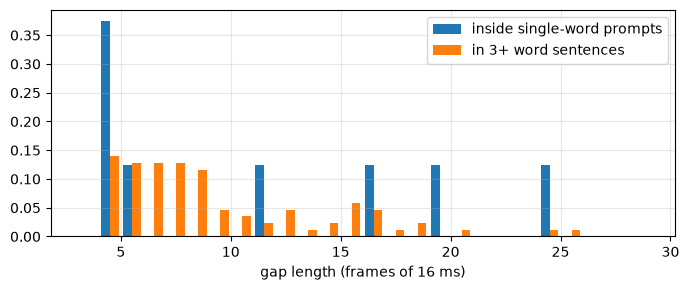

In [3]:
def gaps(r, thr_hi=300, thr_lo=120, run=4):
    loud = np.where(r > thr_hi)[0]
    if len(loud) == 0: return []
    seg = r[loud[0]:loud[-1] + 1] < thr_lo; out, n = [], 0
    for v in seg:
        if v: n += 1
        else:
            if n >= run: out.append(n)
            n = 0
    return out
rows = [dict(words=len(u["tokens"]), gaps=gaps(frame_rms(u["frames"]))) for u in real]
df = pd.DataFrame(rows); df["n_gaps"] = df.gaps.apply(len)
tab = df.groupby("words").agg(prompts=("n_gaps", "size"), mean_gaps=("n_gaps", "mean"), with_a_gap=("n_gaps", lambda s: (s > 0).mean() * 100)).round(2)
tab.columns = ["prompts", "avg internal gaps (>=4 quiet frames)", "% of prompts with at least one gap"]
display(tab)
one = [g for row in rows if row["words"] == 1 for g in row["gaps"]]; many = [g for row in rows if row["words"] >= 3 for g in row["gaps"]]
fig, ax = plt.subplots(figsize=(7, 3)); b = np.arange(3, 30)
ax.hist([one, many], bins=b, label=["inside single-word prompts", "in 3+ word sentences"], density=True); ax.set_xlabel("gap length (frames of 16 ms)"); ax.legend(); fig.tight_layout()
print(f"single-word prompts: {len(one)} gaps, median {np.median(one) if one else 0:.0f} frames;  sentences: {len(many)} gaps, median {np.median(many):.0f} frames")

**Reading it:** single words already contain quiet gaps (the weak "s" in "switch", the closure before "tch", "t" or "b").
Their length is the same as the gaps between words in a sentence, so no threshold on loudness can separate the two.
This is the limit of the cutter, not something more tuning can fix.

*Caveat:* the single-word sample is small (10 prompts, 8 gaps in total), so treat the histogram as an illustration; what it does show is that gaps inside single words reach 4-24 frames, overlapping and exceeding the 4-9 frame gaps found in sentences.

## 2. The old approach on real sentences
`voice_dsp`: loudness cutter -> 29 DSP features -> logistic regression. Reproduced here by simulating the firmware's cutter
(same constants as `apps/voice_dsp/main.cpp`) on the recorded audio, with the model trained as `tools/train_export.py` does.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
X1, y1, _ = vf.load_dataset("dataset"); X2, y2, _ = vf.load_dataset("dataset_live", mode="raw")
lr = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000, class_weight="balanced")).fit(np.vstack([X1, X2]), np.concatenate([y1, y2]))
PRE, PAD, TRIG, END, ENDQ, MINW, TAIL, NF = 10, 7, 300.0, 120.0, 4, 5, 3, 42       # firmware constants

def cutter_windows(frames):
    """What apps/voice_dsp would capture from these frames: one 42-frame window per detected word."""
    r = frame_rms(frames); wins, ring, cap, hot, refr, since, quiet, bg = [], [], None, 0, 0, 99, 0, None
    for t in range(len(frames)):
        ring.append(t); ring = ring[-PRE:]; since += 1
        if cap is not None:
            cap.append(t); quiet = quiet + 1 if r[t] < END else 0
            ended = quiet >= ENDQ and len(cap) >= PRE + MINW
            if ended or len(cap) == NF:
                keep = min(len(cap) - quiet + TAIL if ended else len(cap), len(cap)); fl = cap[:keep]; k = 0
                while len(fl) < NF: fl.append(cap[k % PAD]); k += 1
                wins.append(np.concatenate([frames[i] for i in fl[:NF]])); cap = None; refr = 3; hot = 0; since = 0
            continue
        if refr > 0: refr -= 1; hot = 0; continue
        hot = hot + 1 if r[t] > TRIG else 0
        if hot >= 2 and len(ring) == PRE:
            pre = list(ring)
            if bg is not None and since < PRE: pre[:PRE - since] = [bg[i % PAD] for i in range(PRE - since)]
            if bg is None or since >= PRE: bg = pre[:PAD]
            cap = pre; quiet = 0; hot = 0
    return wins

old_seqs, n_windows = [], []
for u in real:
    wins = cutter_windows(u["frames"]); n_windows.append(len(wins)); got = []
    if wins:
        for p in lr.predict_proba([vf.extract(w) for w in wins]):
            c = lr.classes_[int(np.argmax(p))]
            if c in KW and p.max() >= 0.6: got.append(str(c))
    old_seqs.append((got, u["want"]))
e_old, k_old = score(old_seqs)
print(f"energy cutter + 29 features: exact {e_old:.0f}%   keyword error rate {k_old:.0f}%")
right = np.mean([n == len(u["tokens"]) for n, u in zip(n_windows, real)]) * 100
print(f"prompts cut into exactly the right number of words: {right:.0f}%")

energy cutter + 29 features: exact 16%   keyword error rate 65%
prompts cut into exactly the right number of words: 42%


## 3. The CNN
**Input:** log-mel spectrogram, one column per 16 ms frame, 32 mel bands (`kws.logmel`). **Model:** four 1D convolutions over time
(mel bands are the channels) + mean/max pooling + a 5-way classifier: *background, blue, green, off, on*. It looks at 42 frames (0.67 s),
and the firmware runs it every 4 frames (64 ms). No word cutting.

**Training data**, in two stages (`kws.Trainer`):
1. *Synthetic sentences*: isolated word recordings stitched with random gaps, volumes and filler words. Word positions are exactly known.
2. *Real sentences* (the session above): word positions are **not** labelled, so the model's own probabilities are aligned to the prompt's
   keywords (in order) by dynamic programming, and the model is fine-tuned on windows around those positions.

Parameters and cost:

In [5]:
net_syn = KwsCnn(); net_syn.load_state_dict(torch.load("models/kws_pretrain.pt")); net_syn.eval()
net_fin = KwsCnn(); net_fin.load_state_dict(torch.load("models/kws_cnn.pt")); net_fin.eval()
params = sum(p.numel() for p in net_fin.parameters())
macs = sum(t * co * 3 * ci for t, ci, co in [(42, 32, 32), (21, 32, 48), (11, 48, 64), (11, 64, 64)]) + 128 * 5
print(f"{params:,} parameters (BatchNorm adds a few that are folded away on export), about {macs:,} multiply-adds per decision")

30,453 parameters (BatchNorm adds a few that are folded away on export), about 462,976 multiply-adds per decision


Held-out comparison on **real sentences**. For the fine-tuned model, whole *prompt texts* are held out (5 folds): the test sentences have wording
the model was not fine-tuned on. Decoding is exactly the firmware's (stride 4, streaming decoder). This takes a few minutes.

approach,exact %,keyword error rate %
Loudness cutter + 29 DSP features (voice_dsp),16.000000,65.000000
"CNN, synthetic sentences only",47.000000,33.000000
"CNN, + fine-tuned on real sentences (held-out prompt texts)",85.000000,9.000000
(same final model on the sentences it was fine-tuned on: NOT a test),95.000000,3.000000


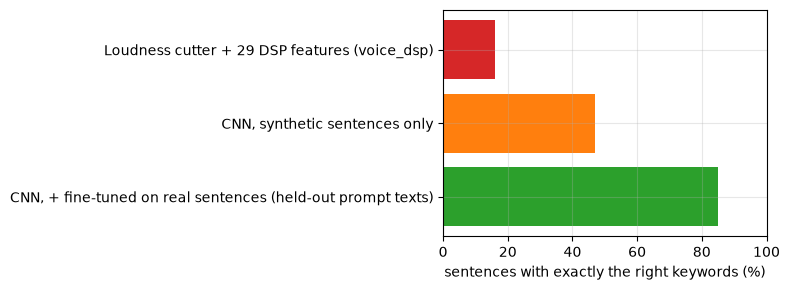

In [6]:
tr = Trainer("models")                                           # loads the saved normalisation; regenerates the synthetic sentences
res_syn, res_ft = tr.cv_by_text(net_syn, folds=5)
e_syn, k_syn = score(res_syn); e_ft, k_ft = score(res_ft)
e_in, k_in = score([(stream_decode(probs(net_fin, u["L"])), u["want"]) for u in tr.real])
table = pd.DataFrame([["Loudness cutter + 29 DSP features (voice_dsp)", e_old, k_old],
                      ["CNN, synthetic sentences only", e_syn, k_syn],
                      ["CNN, + fine-tuned on real sentences (held-out prompt texts)", e_ft, k_ft],
                      ["(same final model on the sentences it was fine-tuned on: NOT a test)", e_in, k_in]],
                     columns=["approach", "exact %", "keyword error rate %"]).round(0)
display(table.style.hide(axis="index"))
fig, ax = plt.subplots(figsize=(8, 3)); ax.barh(table.approach[:3][::-1], table["exact %"][:3][::-1], color=["tab:green", "tab:orange", "tab:red"])
ax.set_xlabel("sentences with exactly the right keywords (%)"); ax.set_xlim(0, 100); fig.tight_layout()

**Earlier experiments** (their scripts were throw-away and are not in the repo, so these numbers were *not* recomputed here; they came out of the same
74 real prompts and exact-keyword-sequence scoring):

| Approach | exact | keyword error |
|---|---|---|
| Same 29 features on sliding windows (no cutting) | about 8 % | - |
| A second CNN that finds word boundaries, then the old classifier | 26-32 % | 48-56 % |
| scikit-learn MLP on log-mel, synthetic sentences only | 46-50 % | 35-43 % |

Takeaways: (a) the synthetic-only models reach 98-100 % on synthetic test sentences but only 42-50 % on real ones: the limit is the gap between
stitched and natural speech, not the model type; (b) learning word boundaries without real boundary labels does not work, while classifying
sliding windows directly does; (c) adding real continuous sentences is what closes the gap.

## 4. What the CNN sees
Class probabilities for one window every 4 frames (64 ms, exactly what the firmware computes) across four real sentences. Dotted lines mark the keywords the streaming decoder reports.

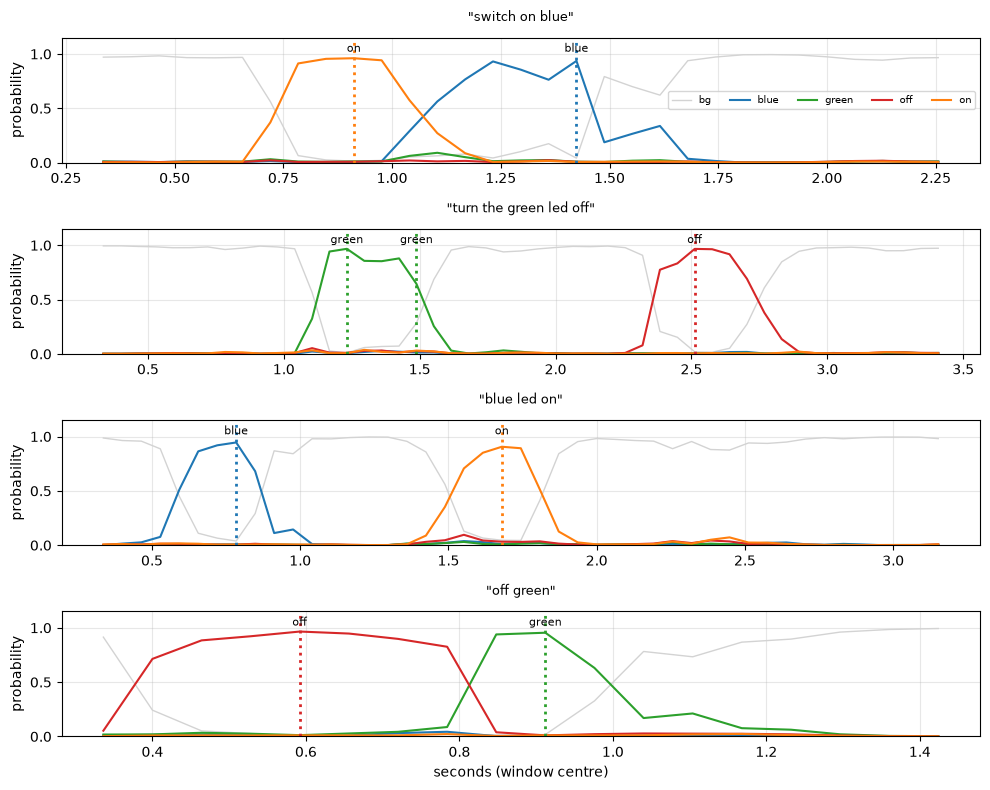

In [7]:
def decode_times(P, theta=THETA, hold=HOLD):
    """Same logic as kws.stream_decode, but also returns the window index of every event."""
    out, cand = [], None
    for i, p in enumerate(P):
        k = 1 + int(np.argmax(p[1:]))
        if p[k] >= theta and (cand is None or p[k] > cand[1]): cand = [k, p[k], 0, i]
        elif cand is not None: cand[2] += 1
        if cand is not None and cand[2] >= hold:
            out.append((CLASSES[cand[0]], cand[3])); cand = None
    if cand is not None: out.append((CLASSES[cand[0]], cand[3]))
    return out
names = ["switch on blue", "turn the green led off", "blue led on", "off green"]
colors = {"bg": "lightgray", "blue": "tab:blue", "green": "tab:green", "off": "tab:red", "on": "tab:orange"}
fig, axs = plt.subplots(len(names), 1, figsize=(10, 8), sharex=False)
for ax, name in zip(axs, names):
    u = next(u for u in tr.real if u["text"] == name); P = probs(net_fin, u["L"], STRIDE); t = (np.arange(len(P)) * STRIDE + W // 2) * 0.016
    for c, k in enumerate(CLASSES): ax.plot(t, P[:, c], color=colors[k], lw=1.5 if k != "bg" else 1, label=k)
    for k, i in decode_times(P): ax.axvline(t[i], color=colors[k], ls=":", lw=2); ax.text(t[i], 1.02, k, ha="center", fontsize=8)
    ax.set_title(f'"{name}"', fontsize=9, pad=12); ax.set_ylim(0, 1.15); ax.set_ylabel("probability")
axs[0].legend(ncol=5, fontsize=7, loc="center right"); axs[-1].set_xlabel("seconds (window centre)"); fig.tight_layout()

## 5. Where it fails (held-out prompt texts)

In [8]:
rows = []
for u_text, (got, want) in zip([u["text"] for u in tr.real], res_ft) if False else []: pass
texts = [u["text"] for u in tr.real]                 # res_ft is ordered by fold, so rebuild the matching text order
folds = 5; ts = sorted(set(texts)); rr = np.random.default_rng(0)
errors = pd.DataFrame([dict(wanted=w, heard=g) for g, w in res_ft if collapse(g) != w])
print(f"{len(errors)} of {len(res_ft)} held-out sentences not exactly right")
display(errors.head(20))
from collections import Counter
miss = Counter(); extra = Counter()
for g, w in res_ft:
    g = collapse(g)
    for k in set(w) - set(g): miss[k] += 1
    for k in set(g) - set(w): extra[k] += 1
print("keywords missed in at least one position:", dict(miss), "\nkeywords reported although not said:", dict(extra))

11 of 74 held-out sentences not exactly right


,wanted,heard
0,"[blue, on]","[blue, on, on, blue, blue]"
1,"[off, green]",[]
2,"[green, on]",[on]
3,"[blue, on]","[blue, blue]"
4,"[blue, on]",[on]
5,"[blue, on]",[blue]
6,"[on, green]","[green, green]"
7,"[on, blue]",[blue]
8,"[green, off]","[green, green]"
9,"[green, off]","[off, off]"


keywords missed in at least one position: {'green': 4, 'off': 2, 'on': 4, 'blue': 1} 
keywords reported although not said: {}


## 6. Is the firmware code the same model?
`tools/check_cnn.py` compiles `common/kws_cnn.cpp` (the code that runs on the board) for the Mac, feeds it real recordings and compares window by window
with PyTorch, including the decoder's events.

In [9]:
out = subprocess.run([sys.executable, "tools/check_cnn.py"], capture_output=True, text=True)
print(out.stdout or out.stderr)

25 utterances, 741 windows compared
largest probability difference C++ vs PyTorch: 4.14e-06
windows where the predicted class differs:     0
utterances with identical decoder events:      25/25



## 7. The live test on the board
`pixi run cnn-test`: prompts on a timer, the board's `EV` / `CMD` lines are collected. The first version of the tool assigned events to the prompt on screen
at that moment, which mis-scored late or early speech (it showed 8 %). The tool now aligns the *whole* keyword stream with the whole prompt stream
(edit distance), which does not depend on timing. Below: the saved log of the first session, re-scored.

In [10]:
import cnn_session
log = sorted(glob.glob("logs/cnn_session_*.json"))[-1]
rows = json.load(open(log))
if isinstance(rows, list):                                # first-session log format (events already grouped per prompt)
    texts, heard, cmds = [r["text"] for r in rows], [g for r in rows for g in r["got"]], [c for r in rows for c in r["cmds"]]
else:
    texts, heard, cmds = rows["prompts"], rows["heard"], rows["commands"]
print("log:", log); cnn_session.summarize(texts, heard, cmds)

log: logs/cnn_session_20261016_053003.json
✗ switch on blue               +green extra, on, blue
  on                           on
  blue led off                 blue, off
✗ switch on green              on, green MISSED
  turn the green led off       green, off
  green led off                green, off
✗ blue                         blue MISSED
  blue off                     blue, off
  blue light on                blue, on
  blue on                      blue, on
✗ green led off                green, off MISSED
  turn off the green led       off, green
  switch on green              on, green
  green led on                 green, on
  please blue on               blue, on
  green led on                 green, on
  turn the blue led on         blue, on
  switch off green             off, green
  please blue on               blue, on
  light                        
  the                          
✗ switch off green             off, green MISSED
  turn the green led off       green, off
 

## 8. Cost on the chip, and what is not proven
* **Flash:** the weights are 117 KB of floats (`common/cnn_params.h`); the whole app is about 182 KB of the 1 MB.
* **Speed:** about 463 k multiply-adds per decision; estimated 15-20 ms in plain float C++ on the 64 MHz Cortex-M4F. **Not measured here**:
  the firmware prints the real value (`cnn ... ms`) every 2 s on the serial monitor.
* **One speaker, one microphone, one room.** Fine-tuning used 74 sentences from one five-minute session by one person, and the same filler
  words (switch, turn, please, led, light, the) appear in training and test. Another voice, or new filler words, will do worse; this was not measured.
* The live score (90 % of keywords, 93 % of colour+action commands) comes from one 36-prompt session, not a benchmark.
* A keyword said within about 190 ms of a stronger one can be dropped by the decoder (suspected cause of some misses; untested fix).

**Experiments still to run** (each scored with held-out prompt texts): delta features and level-invariant normalisation; window length and mel-band count;
more realistic synthetic sentences (overlapped, speed- and pitch-varied words); decoder threshold / hold / smoothing and per-word thresholds;
word-order hints; int8 quantisation; more speakers.